# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama: Muhammad Rangga Pratama Cellyanda
- NIM: 241011401662
- Kelas: Reg B / Reg C *(silakan pilih kelas yang benar)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 62
np.set_printoptions(precision=4, suppress=True)
print("RANDOM_STATE =", RANDOM_STATE)

RANDOM_STATE = 62


In [2]:
# Fungsi train_test_split buatan sendiri menggunakan NumPy
def train_test_split(X, y, test_size=0.2, random_state=62):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("Jumlah baris X dan y harus sama.")
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Fungsi metrik klasifikasi buatan sendiri
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int).ravel()
    y_pred = np.asarray(y_pred).astype(int).ravel()
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ])

def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true).ravel() == np.asarray(y_pred).ravel())

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def precision_recall_f1(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


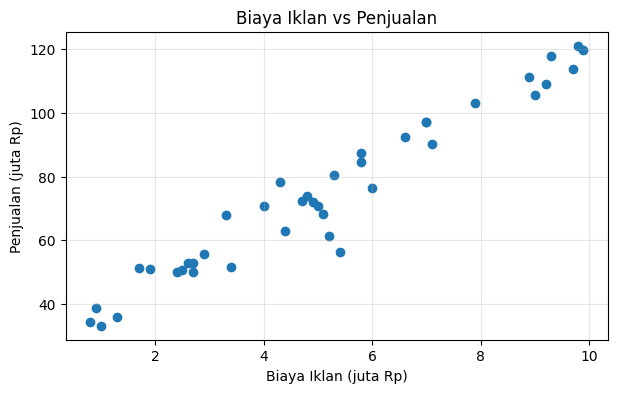

In [3]:
# Jawaban A1
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris data:", len(ads))

X = ads[["BiayaIklan"]].to_numpy(dtype=float)  # bentuk (n, 1)
y = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3 - Linear Regression dengan Normal Equation
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

lin_model = LinearRegression().fit(X_train, y_train)
y_train_pred = lin_model.predict(X_train)
y_test_pred = lin_model.predict(X_test)
print(f"Intercept (b): {lin_model.intercept_:.4f}")
print(f"Koefisien (m): {lin_model.coef_[0]:.4f}")
print(f"Persamaan: ŷ = {lin_model.intercept_:.4f} + ({lin_model.coef_[0]:.4f} × BiayaIklan)")

Intercept (b): 28.7373
Koefisien (m): 9.0379
Persamaan: ŷ = 28.7373 + (9.0379 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Nilai koefisien menunjukkan perkiraan perubahan penjualan untuk setiap kenaikan biaya iklan sebesar Rp1 juta. Jika koefisien bernilai positif, penjualan diperkirakan meningkat sebesar nilai koefisien tersebut (dalam juta rupiah), dengan asumsi hubungan linear pada data.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4 - Metrik regresi buatan sendiri
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    return mae, mse, rmse, r2

train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics = regression_metrics(y_test, y_test_pred)
metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Testing"],
    columns=["MAE", "MSE", "RMSE", "R²"]
)
display(metrics_df.round(4))

,MAE,MSE,RMSE,R²
Training,4.8196,41.6658,6.4549,0.9212
Testing,3.3237,13.7988,3.7147,0.9868


**Jawaban A4 (analisis):**

MAE, MSE, dan RMSE mengukur besar kesalahan prediksi; semakin kecil nilainya, semakin dekat prediksi dengan nilai sebenarnya. R² menunjukkan seberapa baik model menjelaskan variasi penjualan dan semakin mendekati 1 umumnya semakin baik. Bandingkan nilai training dan testing pada tabel: jika hasil testing jauh lebih buruk, model mungkin kurang mampu melakukan generalisasi.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Learning rate 0.001: intercept=24.78, koefisien=9.685, loss akhir=44.73


Learning rate 0.02: intercept=28.74, koefisien=9.038, loss akhir=41.67
Learning rate 0.1: intercept=-7.471e+151, koefisien=-4.573e+152, loss akhir=nan

Normal Equation:
intercept=28.7373, koefisien=9.0379


/opt/pyvenv/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


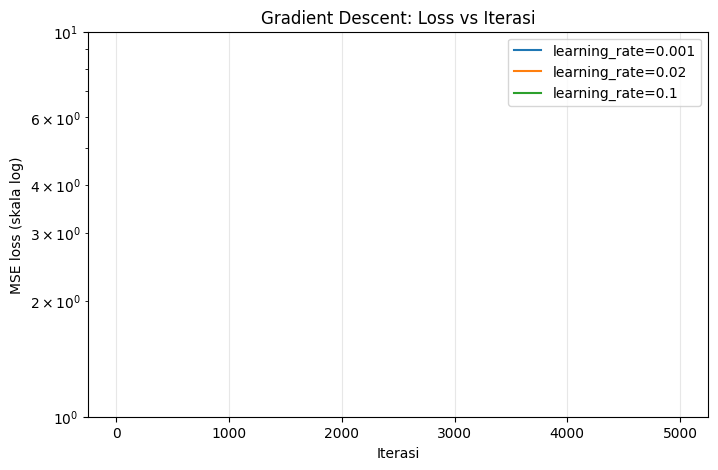

In [7]:
# Jawaban A5 - Gradient Descent
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(self.n_iterations):
                pred = X_b @ theta
                error = pred - y
                grad = (2 / len(y)) * (X_b.T @ error)
                theta -= self.learning_rate * grad
                loss = np.mean((X_b @ theta - y) ** 2)
                self.loss_history.append(loss)
                if not np.isfinite(loss) or not np.all(np.isfinite(theta)):
                    self.loss_history.extend([np.nan] * (self.n_iterations - len(self.loss_history)))
                    break
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

gd_models = {}
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    print(f"Learning rate {lr}: intercept={model.intercept_:.4g}, koefisien={model.coef_[0]:.4g}, "
          f"loss akhir={model.loss_history[-1]:.4g}")

print("\nNormal Equation:")
print(f"intercept={lin_model.intercept_:.4f}, koefisien={lin_model.coef_[0]:.4f}")

plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    loss = np.asarray(model.loss_history, dtype=float)
    plt.plot(np.arange(1, len(loss)+1), loss, label=f"learning_rate={lr}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Jawaban A5 (analisis):**

Bandingkan kurva loss dengan hasil Normal Equation. Learning rate 0.001 biasanya bergerak lebih lambat karena langkah pembaruan kecil. Learning rate 0.02 diharapkan lebih cepat mendekati solusi, sedangkan 0.1 dapat terlalu besar sehingga loss melonjak atau menjadi tidak stabil. Jika grafik menunjukkan nilai sangat besar atau tidak hingga, itu menandakan divergensi; hasil aktualnya dapat dilihat pada grafik dan nilai loss akhir.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

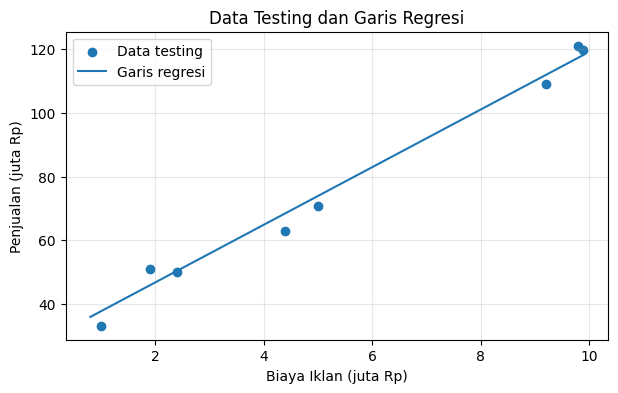

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,69.408
1,7.0,92.002
2,12.0,137.192


In [8]:
# Jawaban A6 - Plot testing dan prediksi
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(min(X[:, 0]), max(X[:, 0]), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], lin_model.predict(x_line), label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = lin_model.predict(biaya_baru)
display(pd.DataFrame({"BiayaIklan (juta Rp)": biaya_baru.ravel(),
                      "PrediksiPenjualan (juta Rp)": prediksi_penjualan}).round(3))

**Jawaban A6 (analisis):**

Prediksi pada biaya iklan 4,5 dan 7 juta lebih dapat dipertimbangkan jika nilainya masih berada dalam rentang data yang diamati. Prediksi 12 juta merupakan ekstrapolasi apabila melampaui rentang data, sehingga lebih tidak dapat dipercaya karena pola hubungan di luar data belum teruji dan belum tentu tetap linear.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah kelas Spam:


,Jumlah
Spam,
Bukan Spam,35
Spam,25


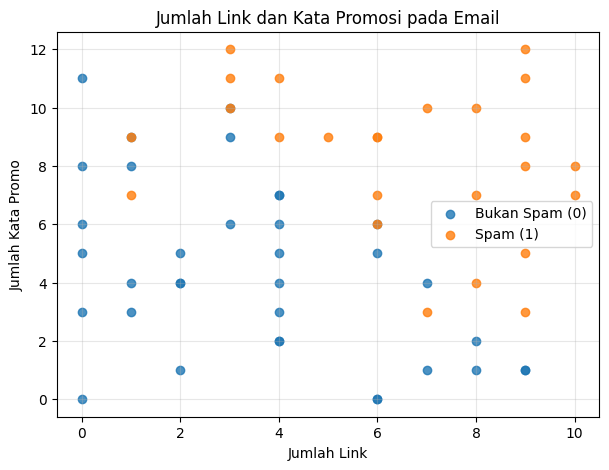

In [9]:
# Jawaban B1
email = pd.read_csv("Email_Data.csv")
display(email.head())
print("\nJumlah kelas Spam:")
display(email["Spam"].value_counts().sort_index().rename(index={0:"Bukan Spam", 1:"Spam"}).to_frame("Jumlah"))

X_email = email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7, 5))
for label, nama, warna in [(0, "Bukan Spam (0)", "tab:blue"), (1, "Spam (1)", "tab:orange")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=nama, alpha=0.8)
plt.title("Jumlah Link dan Kata Promosi pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -8.5159
Koefisien (m1, m2): [0.7226 0.7523]
P(Spam) = sigmoid(-8.5159 + (0.7226 × JumlahLink) + (0.7523 × KataPromo))


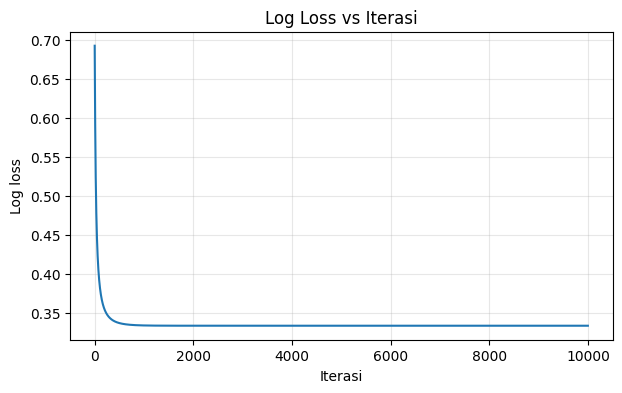

In [10]:
# Jawaban B2 - Logistic Regression dengan Gradient Descent
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        # Standarisasi fitur agar gradient descent stabil; koefisien dikonversi kembali ke fitur asli.
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1
        Xs = (X - self.mean_) / self.std_
        X_b = np.c_[np.ones(len(Xs)), Xs]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            p = sigmoid(X_b @ theta)
            eps = 1e-12
            loss = -np.mean(y*np.log(p+eps) + (1-y)*np.log(1-p+eps))
            self.loss_history.append(loss)
            grad = X_b.T @ (p-y) / len(y)
            theta -= self.learning_rate * grad
        self.intercept_ = theta[0] - np.sum(theta[1:] * self.mean_ / self.std_)
        self.coef_ = theta[1:] / self.std_
        return self
    def predict_proba(self, X):
        return sigmoid(self.intercept_ + np.asarray(X, dtype=float) @ self.coef_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print(f"Intercept (b): {log_model.intercept_:.4f}")
print("Koefisien (m1, m2):", np.round(log_model.coef_, 4))
print(f"P(Spam) = sigmoid({log_model.intercept_:.4f} + ({log_model.coef_[0]:.4f} × JumlahLink) + ({log_model.coef_[1]:.4f} × KataPromo))")

plt.figure(figsize=(7, 4))
plt.plot(log_model.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Log Loss vs Iterasi")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Standarisasi fitur digunakan saat pelatihan agar langkah gradient descent lebih stabil, lalu koefisien dikembalikan ke skala fitur asli untuk persamaan yang ditampilkan. Jika kurva log loss menurun lalu mendatar, model telah belajar dan mendekati konvergensi. Periksa grafik hasil eksekusi untuk memastikan pola tersebut.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3 - Evaluasi testing
y_test_pred_email = log_model.predict(X_test_email, threshold=0.5)
cm = confusion_matrix(y_test_email, y_test_pred_email)
precision, recall, f1 = precision_recall_f1(y_test_email, y_test_pred_email)
print("Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):")
print(cm)
print(f"Accuracy : {accuracy_score(y_test_email, y_test_pred_email):.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Confusion matrix (baris aktual 0/1, kolom prediksi 0/1):
[[8 0]
 [0 7]]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000
TN=8, FP=0, FN=0, TP=7


**Jawaban B3 (analisis):**

FP adalah email bukan spam yang keliru ditandai sebagai spam, sehingga pesan penting bisa masuk folder spam. FN adalah email spam yang keliru dianggap bukan spam, sehingga spam tetap masuk ke kotak masuk. Untuk pengguna umum, FP dapat lebih merugikan jika menyebabkan email penting terlewat; tetapi FN juga mengganggu karena spam lolos. Pilihan prioritas bergantung pada kebutuhan pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.5159 + (0.7226 × JumlahLink)) / (0.7523)


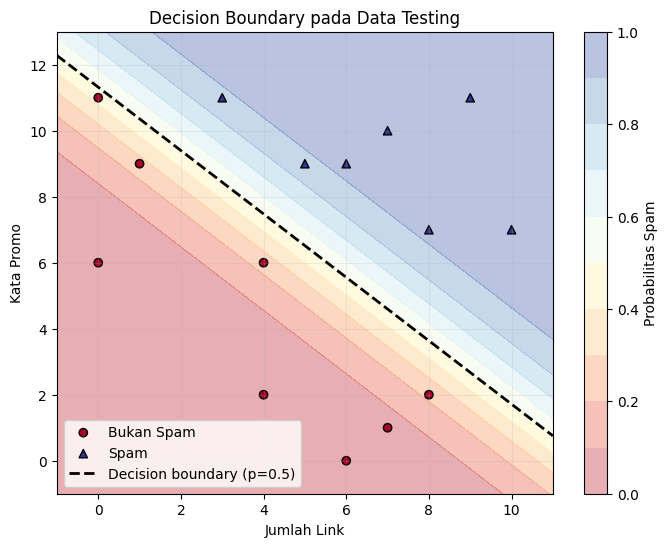

,JumlahLink,KataPromo,Aktual,Prediksi


In [12]:
# Jawaban B4 - Decision Boundary dan salah klasifikasi
b = log_model.intercept_
m1, m2 = log_model.coef_
if abs(m2) > 1e-12:
    print(f"Decision boundary: KataPromo = -({b:.4f} + ({m1:.4f} × JumlahLink)) / ({m2:.4f})")
else:
    print("Koefisien KataPromo mendekati nol, sehingga boundary tidak dapat ditampilkan sebagai fungsi KataPromo.")

x1_min, x1_max = X_email[:, 0].min()-1, X_email[:, 0].max()+1
x2_min, x2_max = X_email[:, 1].min()-1, X_email[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = log_model.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probs, levels=np.linspace(0, 1, 11), alpha=0.35, cmap="RdYlBu")
plt.colorbar(label="Probabilitas Spam")
for label, nama, marker in [(0, "Bukan Spam", "o"), (1, "Spam", "^")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], c=y_test_email[mask],
                cmap="RdYlBu", vmin=0, vmax=1, marker=marker, edgecolors="black", label=nama)
if abs(m2) > 1e-12:
    x_boundary = np.linspace(x1_min, x1_max, 200)
    y_boundary = -(b + m1*x_boundary) / m2
    valid = (y_boundary >= x2_min) & (y_boundary <= x2_max)
    plt.plot(x_boundary[valid], y_boundary[valid], "k--", linewidth=2, label="Decision boundary (p=0.5)")
wrong = y_test_email != y_test_pred_email
if np.any(wrong):
    plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], s=150, facecolors="none",
                edgecolors="red", linewidths=2, label="Salah klasifikasi")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary pada Data Testing")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

wrong_df = pd.DataFrame(X_test_email[wrong], columns=["JumlahLink", "KataPromo"])
wrong_df["Aktual"] = y_test_email[wrong]
wrong_df["Prediksi"] = y_test_pred_email[wrong]
display(wrong_df)

**Jawaban B4 (analisis):**

Garis decision boundary menunjukkan batas probabilitas spam 0,5. Titik yang dilingkari merah adalah email testing yang salah diklasifikasikan; tabel di bawah grafik menampilkan jumlah link, kata promo, label aktual, dan prediksi untuk setiap kesalahan. Jika tabel kosong, berarti tidak ada kesalahan pada data testing.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5 - Eksperimen threshold
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (log_model.predict_proba(X_test_email) >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    cm_t = confusion_matrix(y_test_email, pred)
    p_t, r_t, f1_t = precision_recall_f1(y_test_email, pred)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    threshold_rows.append({
        "Threshold": threshold, "TN": tn_t, "FP": fp_t, "FN": fn_t, "TP": tp_t,
        "Precision": p_t, "Recall": r_t
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

# Pilih threshold berdasarkan keseimbangan precision-recall (F1 tertinggi)
f1_by_threshold = {
    t: precision_recall_f1(y_test_email, pred)[2]
    for t, pred in threshold_predictions.items()
}
chosen_threshold = max(f1_by_threshold, key=f1_by_threshold.get)
print("Threshold pilihan berdasarkan F1 tertinggi:", chosen_threshold)
print("F1 per threshold:", {t: round(v, 4) for t, v in f1_by_threshold.items()})

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,7,1,0,7,0.875,1.0
1,0.5,8,0,0,7,1.000,1.0
2,0.7,8,0,0,7,1.000,1.0


Threshold pilihan berdasarkan F1 tertinggi: 0.5
F1 per threshold: {0.3: np.float64(0.9333), 0.5: np.float64(1.0), 0.7: np.float64(1.0)}


**Jawaban B5 (analisis):**

Threshold lebih rendah membuat lebih banyak email diprediksi sebagai spam; biasanya recall naik, tetapi FP dapat bertambah sehingga precision bisa turun. Threshold lebih tinggi membuat model lebih selektif menandai spam; biasanya precision naik, tetapi recall bisa turun. Threshold yang dipilih di kode adalah threshold dengan F1 tertinggi dari tiga pilihan, agar precision dan recall seimbang berdasarkan hasil data testing.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6 - Prediksi email baru
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
email_baru["ProbabilitasSpam"] = log_model.predict_proba(X_baru)
email_baru["Threshold"] = chosen_threshold
email_baru["Prediksi"] = (email_baru["ProbabilitasSpam"] >= chosen_threshold).astype(int)
email_baru["Kelas"] = email_baru["Prediksi"].map({0: "Bukan Spam", 1: "Spam"})
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,ProbabilitasSpam,Threshold,Prediksi,Kelas
0,E1,1,2,0.0019,0.5,0,Bukan Spam
1,E2,5,6,0.4039,0.5,0,Bukan Spam
2,E3,9,10,0.9960,0.5,1,Spam
3,E4,2,11,0.7693,0.5,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena hasil akhirnya digunakan untuk menentukan kelas, misalnya spam atau bukan spam. Fungsi sigmoid mengubah nilai perhitungan model menjadi probabilitas antara 0 dan 1. Probabilitas itu kemudian dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:**

Normal Equation menghitung koefisien secara langsung melalui operasi matriks tanpa proses iterasi. Gradient Descent memperbarui koefisien sedikit demi sedikit untuk menurunkan loss. Gradient Descent cocok untuk data besar atau fitur banyak ketika perhitungan langsung menjadi berat.

**Jawaban C3:**

Data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai saat pelatihan. Jika hanya mengukur data training, hasilnya bisa terlihat bagus tetapi belum tentu berlaku pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data baru.

**Jawaban C4:**

Linear Regression memprediksi nilai numerik, sehingga MSE mengukur rata-rata kuadrat selisih antara prediksi dan nilai sebenarnya. Logistic Regression memprediksi probabilitas kelas, sehingga log loss menilai seberapa tepat probabilitas tersebut terhadap label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah.

**Jawaban C5:**

Hasil dapat berbeda karena pembagian data training dan testing bisa berbeda akibat random_state yang berbeda. Hasil juga dipengaruhi inisialisasi parameter, learning rate, jumlah iterasi, preprocessing, dan threshold klasifikasi. Karena itu, perbandingan harus menggunakan pengaturan eksperimen yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus - perbandingan dengan scikit-learn
# Bagian bonus ini satu-satunya bagian yang menggunakan scikit-learn.
try:
    from sklearn.linear_model import LinearRegression as SkLinearRegression
    from sklearn.linear_model import LogisticRegression as SkLogisticRegression
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score as sk_accuracy

    sk_lin = SkLinearRegression().fit(X_train, y_train)
    sk_y_pred = sk_lin.predict(X_test)
    print("Linear Regression scikit-learn")
    print("Intercept:", sk_lin.intercept_, "| Koefisien:", sk_lin.coef_)
    print("MAE:", mean_absolute_error(y_test, sk_y_pred),
          "| MSE:", mean_squared_error(y_test, sk_y_pred),
          "| R2:", r2_score(y_test, sk_y_pred))

    # LogisticRegression sklearn memiliki regularisasi default; C besar mengurangi pengaruh regularisasi.
    sk_log = SkLogisticRegression(C=1e6, max_iter=10000)
    sk_log.fit(X_train_email, y_train_email)
    sk_pred = sk_log.predict(X_test_email)
    print("\nLogistic Regression scikit-learn")
    print("Intercept:", sk_log.intercept_[0], "| Koefisien:", sk_log.coef_[0])
    print("Accuracy:", sk_accuracy(y_test_email, sk_pred))
    print("Accuracy implementasi sendiri:", accuracy_score(y_test_email, y_test_pred_email))
except ImportError:
    print("scikit-learn belum tersedia. Bagian bonus dapat dilewati sesuai instruksi tugas.")

Linear Regression scikit-learn
Intercept: 28.737321064734445 | Koefisien: [9.0379]
MAE: 3.3237236224031843 | MSE: 13.798806816527124 | R2: 0.9868098505680494

Logistic Regression scikit-learn
Intercept: -8.515923767891557 | Koefisien: [0.7226 0.7523]
Accuracy: 1.0
Accuracy implementasi sendiri: 1.0


**Jawaban Bonus (analisis):**

Hasil Linear Regression scikit-learn seharusnya mendekati implementasi Normal Equation karena keduanya mencari solusi kuadrat terkecil. Hasil Logistic Regression bisa berbeda karena scikit-learn menggunakan optimasi dan regularisasi secara default, sedangkan implementasi sendiri menggunakan gradient descent tanpa regularisasi. Perbedaan preprocessing, toleransi berhenti, dan parameter model juga dapat memengaruhi koefisien serta evaluasi.